# 10-OpenCV识别与目标跟踪


## 1. 本篇范围与案例目标

第 09 篇介绍了数字图像、OpenCV、摄像头输入和 ROI。本篇继续处理图像中的内容：识别物体的颜色与形状，找出桌面上的新增物体，持续输出目标位置，并了解二维码解码与人脸检测。

本篇依据 `opencv.pptx` 整理。原课标题是“数字图像基础与OpenCV入门”，本篇覆盖第 **10、16—18、21—30 页**，包含六个识别与跟踪案例，以及传统视觉方法的优势和局限。

PPT 提供了案例功能、主要 API、处理思路与部分输出格式，没有附这些案例的完整程序、阈值参数或测试结果。下面按原课顺序讲清已有内容。第 12—15、19—20 页的标定、透视变换和姿态测量归入第 11 篇；第 31—34 页的数据学习与 CNN 过渡留给后续笔记。


## 2. 案例三：智能颜色分拣机

智能颜色分拣机（Intelligent Color Sorter）的视觉任务是**识别不同颜色的物体，并输出它们在图像中的位置**。

课件给出的输出格式是：

```text
[{"type": "color", "value": "red", "position_pixels": [x, y]}]
```

`type` 标记结果类型，`value` 表示识别到的颜色，`position_pixels` 表示像素位置。外层列表可以容纳多个结果。

**格式说明：**本篇沿用课件的 `[x, y]` 占位写法，它表示需要填入实际坐标，并不是可直接解析的 JSON 数值。本篇的坐标顺序均为先横向 `x`、后纵向 `y`，访问数组时仍写成 `image[y, x]`。

### 2.1 为什么转到 HSV

同一个红色物体在亮处与暗处的 BGR 数值可能差异很大。如果只依靠一组固定的 BGR 数值判断颜色，容易受到光照影响。

HSV 将颜色的种类、鲜艳程度与明暗分开表达：

| 分量 | 名称 | 含义 |
|---|---|---|
| H | Hue，色相 | 颜色种类，例如红、橙、黄 |
| S | Saturation，饱和度 | 颜色的纯度或鲜艳程度 |
| V | Value，明度 | 颜色的亮度 |

课件以 H 为主要判断依据：为目标颜色设定色相范围，从画面中提取对应区域。

> **补充说明：**HSV 有助于把颜色与亮度分开处理，但仍会受光照、阴影与相机成像影响。实际颜色阈值通常还要约束 S、V，不能把“使用 HSV”理解为已经消除了光照影响。PPT 没有提供具体阈值。


## 3. 颜色分割、轮廓与中心位置

课件为颜色分拣列出以下核心技术：

| 环节 | 课件中的技术或 API | 作用 |
|---|---|---|
| 颜色空间转换 | BGR to HSV | 将图像转换到便于按颜色筛选的空间 |
| 颜色阈值分割 | `cv2.inRange` | 筛出落在目标颜色范围内的像素 |
| 轮廓检测 | `cv2.findContours` | 从分割结果中查找区域边界 |
| 矩计算 | `cv2.moments` | 用区域的几何信息计算中心等量 |

阈值分割的结果通常称为**掩码（Mask）**：符合条件的位置保留，不符合条件的位置排除。后续轮廓分析处理的是这些被保留的区域。

**补充原理：**用图像矩计算区域质心时，若零阶矩 $M_{00}\ne 0$，中心可表示为：

$$
c_x = \frac{M_{10}}{M_{00}},\qquad
c_y = \frac{M_{01}}{M_{00}}
$$

其中 $M_{00}$ 表示区域的总量，$M_{10}$ 和 $M_{01}$ 分别表达沿横向、纵向的加权位置。这是对课件“矩计算”的简短解释，不是课件给出的完整实现。计算时需要处理空区域或 $M_{00}=0$ 的情况，避免除以零。

颜色分拣的视觉结果提供颜色标签与像素位置。要让机械臂到达该位置，还需要把像素坐标转换为工作空间坐标，这一步在第 11 篇讨论。


## 4. 案例四：形状分拣机

形状分拣机（Shape Sorter）的功能是识别不同形状的物体，并输出位置信息。课件格式如下：

```text
[{"type": "shape", "value": "circle", "position_pixels": [x, y]}]
```

### 4.1 从图像到简化轮廓

课件列出的预处理包括灰度化、二值化与模糊，核心识别方法是轮廓逼近 `cv2.approxPolyDP`。

`cv2.findContours` 找到的轮廓可能包含很多点。`cv2.approxPolyDP` 用更少的顶点逼近原轮廓，把复杂边界表示为一个简化多边形，再用顶点数量判断基本形状。

| 逼近后的顶点数 | 课件采用的判断 |
|---|---|
| 3 个 | 三角形 |
| 4 个 | 矩形或正方形 |
| 超过 8 个 | 通常可以近似为圆形 |

这里的灰度化减少颜色维度，二值化帮助分离目标与背景，模糊可用于减轻噪声影响。PPT 没有给出具体处理参数或完整调用顺序。

> **补充说明：**顶点数是简化场景中的判断规则。4 个顶点一般只能说明它是四边形，判定矩形还需检查角度等条件；超过 8 个顶点也不能保证是圆。逼近精度、噪声和遮挡都会改变顶点数，因此要把这张表理解为课件的启发式规则。


## 5. 案例五：通过背景差分检测桌面物体

“清台高手”（Table Cleaner）使用背景差分检测桌面上的物体。视觉部分输出物体位置，课件格式是：

```text
[{"type": "object", "position_pixels": [x, y]}]
```

这个案例的依据是：已知一张没有物体的桌面图像，再观察当前画面与它有什么差异。

### 5.1 课件中的处理步骤

1. **捕获背景。**先拍摄一张没有任何物体的纯净背景图像。
2. **计算差异。**用当前视频帧与背景图像逐像素比较，通过 `cv2.absdiff` 得到差异图像。
3. **阈值处理。**未变化的位置差异接近 `0`，新增物体或发生变化的位置差异较大。设定阈值，将变化区域提取成二值掩码。
4. **轮廓分析。**在掩码上分析轮廓，找到新出现的物体。

**补充说明：**`cv2.absdiff` 计算的是逐元素的绝对差。对应图像需要在尺寸、类型与通道上兼容，比较的位置也应保持对齐。

### 5.2 方法的适用条件

课件明确指出：**这种方法对光线变化非常敏感。**即使桌面物体没有变化，光照变化也会让像素值发生变化，进而产生差异区域。

**补充说明：**这个简单案例依赖固定视角与较稳定的背景。相机移动、阴影或背景自身变化也可能被当作前景。背景差分检测到的是“画面发生变化的区域”，不能单凭差异值判断物体类别。


## 6. 案例六：实时目标跟随

实时目标跟随（Real-time Target Follower）的功能是持续跟踪特定颜色的物体，输出当前目标位置：

```text
{"type": "track_target", "position_pixels": [x, y]}
```

与颜色分拣输出一个结果列表不同，这个案例聚焦一个目标，因此课件给出的结果是单个对象。

### 6.1 复用颜色分拣流程

课件提出复用案例三的处理思路，并调整为关注单一、最大的目标。每帧执行：

1. 将 BGR 图像转换为 HSV。
2. 使用 `cv2.inRange` 创建只包含目标颜色的掩码。
3. **可选：**用腐蚀、膨胀等形态学操作减轻掩码噪声。
4. 使用 `cv2.findContours` 查找掩码中的轮廓。
5. 找出面积最大的轮廓，把它作为当前跟踪目标。
6. 计算该轮廓的中心点，输出实时位置。

形态学操作处理的是掩码中的区域结构。课件把这一步列为可选，没有指定操作组合、核大小或迭代次数。

### 6.2 实时性与目标选择

课件强调，实时效果取决于能否高效处理每一帧。新的画面不断到来，目标位置也需要持续更新。

> **补充说明：**“最大轮廓就是目标”是这个案例的选择假设。出现更大的同色物体时，结果可能切换到它；流程没有提供跨帧身份匹配或遮挡后的恢复机制。如果某一帧没有有效轮廓，应明确处理“未检测到目标”，不能把不存在的位置当作当前有效位置。

这个案例输出的是图像中的目标位置。让机械臂或云台实际跟随，还需要后续控制与坐标转换，PPT 本页没有附执行器控制程序。


## 7. 案例九：二维码与条形码解码

课件案例九的功能是从摄像头视频流中自动检测、解码二维码和条形码，采用第三方库 `pyzbar`。

### 7.1 安装课件指定的库

在运行视觉案例的 Python 环境中，执行课件命令：

```powershell
pip install pyzbar
```

课件还提供了镜像安装方式，按需选择一种：

```powershell
pip install pyzbar -i https://mirrors.aliyun.com/pypi/simple/
```

### 7.2 图像采集与码信息读取

`pyzbar` 封装了 ZBar 条码读取引擎。课件的协作方式是：OpenCV 获取图像帧，图像以 NumPy 数组表示，再把这一帧传给 `pyzbar` 的解码函数，得到识别到的码及其信息列表。

这一页没有给出完整解码代码、列表字段示例或识别结果。

> **课件表述修正：**PPT 写“OpenCV 本身不直接提供二维码解码功能”。OpenCV 已提供 `cv2.QRCodeDetector`，可以用于二维码检测与解码。这里应理解为课程选择 `pyzbar` 实现二维码与条形码案例。

**补充依赖说明：**`pyzbar` 依赖 ZBar，能否运行还与平台上的原生库是否可用有关，单独安装 Python 包并不能在所有环境中保证解码成功。


## 8. 案例十：Haar 模型检测人脸

PPT 将案例十命名为“人脸识别视觉初体验”，实际功能是使用 OpenCV 预训练的 Haar 模型**检测人脸**，核心 API 是 `cv2.CascadeClassifier`。

### 8.1 Haar 特征

课件把 Haar 特征解释为简单的黑白矩形模板。将模板放在图像区域上，对白色区域与黑色区域分别求像素和，再按模板规则作差，得到一个特征值。

它描述的是局部明暗关系。模型使用这些特征判断候选区域是否像人脸。

### 8.2 级联分类器

级联（Cascade）把判断过程分成多个阶段：一个区域需要通过所有阶段，才作为人脸检测结果保留下来。

大部分非人脸区域会在早期阶段被排除，后续阶段只处理剩余候选区域，因此能够减少计算量。

课件说明 OpenCV 提供预训练的 XML 模型文件，可以加载后使用。本页没有指定某个模型文件、检测参数或完整程序。

> **补充辨析：**人脸检测回答“哪里有人脸”；人脸身份识别回答“这是谁”。本案例只讲前者，检测到人脸框并不代表已经识别出身份。


## 9. 传统视觉方法面对的变化

前面的案例都依赖明确的判定依据：颜色范围、轮廓顶点、背景差异或预训练的 Haar 特征。课件接着提出传统机器视觉的挑战，观察这些依据在复杂画面中是否仍然成立。

第 24—27 页通过原图展示视角、光照、尺寸、形态、背景、遮挡和类内差异。它们影响图像中的数值、轮廓或可见信息，使受控条件下有效的规则难以直接覆盖所有场景。

**补充辨析：**这里的“传统视觉”指课件讨论的人工特征与规则方法。OpenCV 是工具库，其能力也包含其他方法，不能把这些局限理解为库中所有功能的共同结论。


## 10. 视角与光照变化

### 10.1 视角变化

目标在不同观察方向下，投影外观和可见轮廓可能改变，基于单一外观制定的规则就可能失效。

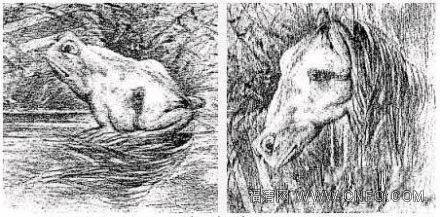

**原图说明：**课件在“视角变化”主题下放置了这幅图案。图中展示的是同一图案可被解读为不同形象，并非同一实物的多视角照片。

### 10.2 光照变化

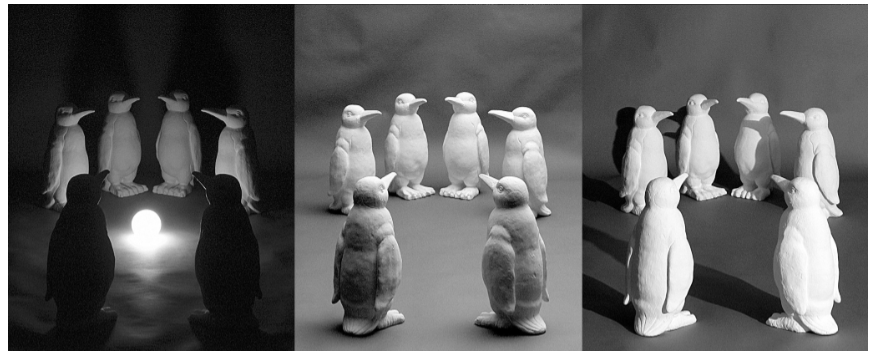

光源位置与强度变化，会改变亮度、阴影和局部对比。相同物体的图像数值因此发生变化，这与颜色阈值和背景差分案例中的光照敏感问题直接相关。


## 11. 尺寸与形态变化

### 11.1 尺寸变化

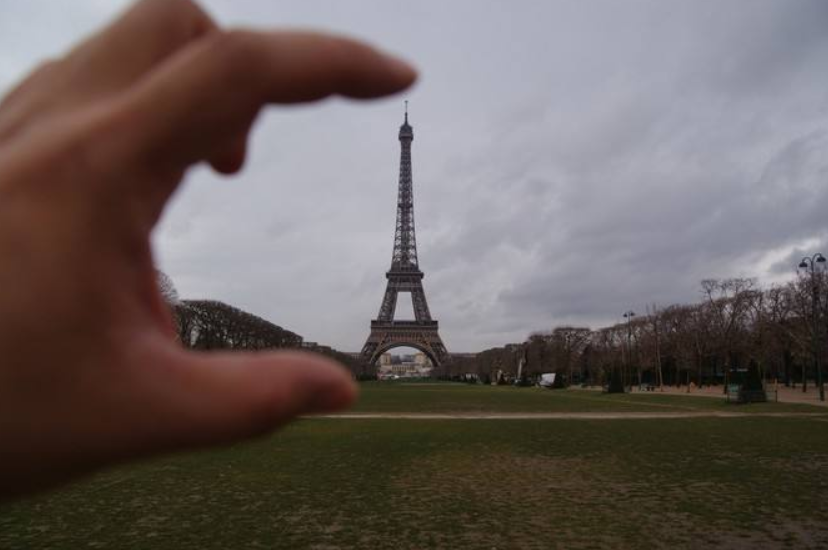

物体在画面中占据的像素尺寸会随观察距离等因素变化。原图用手与远处建筑的关系展示视觉尺度，提醒我们图像中的大小不直接等于实际物理大小。

固定像素尺寸或固定面积的规则，可能只适合一定的观察范围。

### 11.2 形态变化

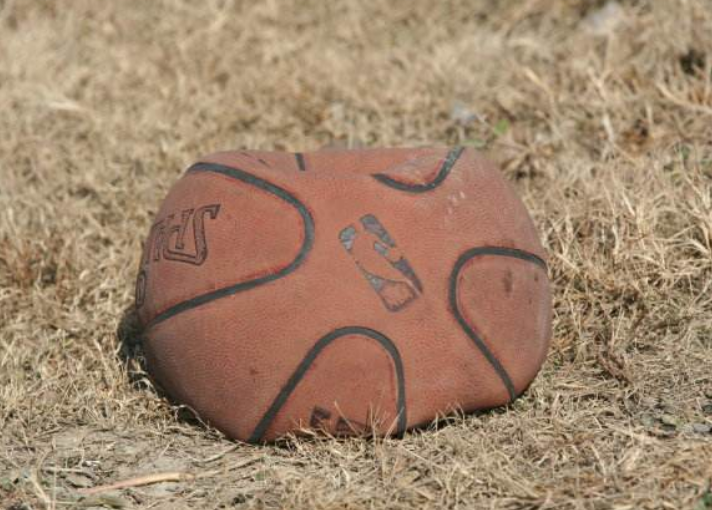

原图中的篮球发生变形，仍保留篮球的外观信息，却已经不具有理想的圆形轮廓。只按“顶点多就接近圆”的规则，难以处理这类形态变化。


## 12. 背景混淆与遮挡

### 12.1 背景混淆

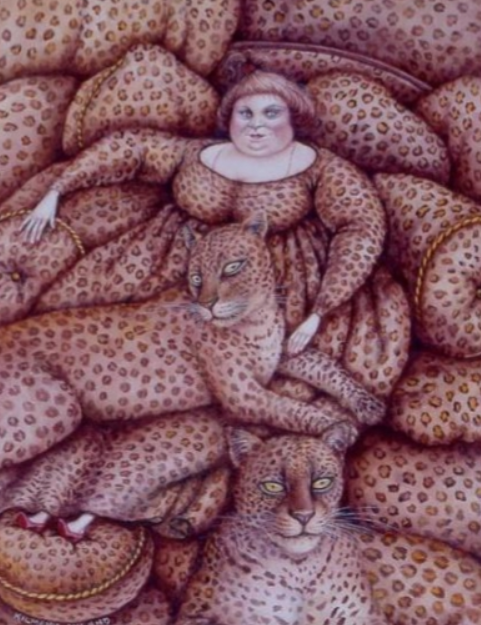

目标与背景具有相似颜色或纹理时，仅依靠局部颜色、边缘等特征，容易把目标与背景混在一起。背景中的同色区域也可能干扰最大轮廓目标选择。

### 12.2 遮挡

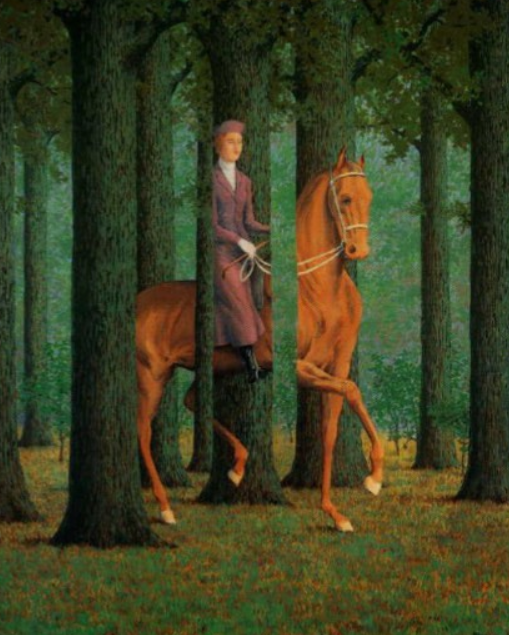

遮挡使目标的一部分不可见，完整轮廓被打断。基于完整形状或连通区域的规则，可能把一个物体分成几部分，也可能因可见信息不足而漏检。


## 13. 同类物体的外观差异

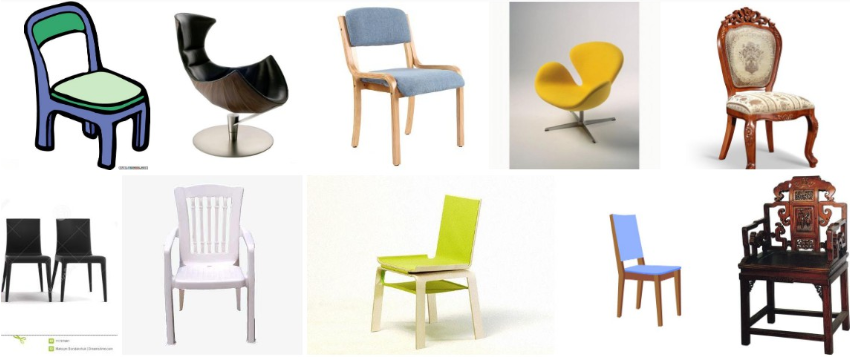

图中的椅子具有不同的材料、颜色、结构和轮廓，却属于同一类物体。这种同一类别内部的外观变化称为**类内差异**。

若只为某一把椅子设计颜色或轮廓规则，很难直接覆盖其他椅子。要识别类别，需要找到对同类对象有效、又能区别其他类别的特征。


## 14. 经典 CV 的核心流程与优势

课件第 28 页将经典视觉方法概括为“手工设计特征 + 简单分类器”。核心流程是：

1. **图像预处理：**先整理输入图像。
2. **手动设计特征提取：**选取能体现任务差异的信息。
3. **特征编码：**把提取的信息整理成后续识别可使用的表示。
4. **分类或识别：**根据特征得到结果。

关键步骤是**特征工程（Feature Engineering）**：由人决定哪些信息能够帮助完成当前任务，并设计如何提取它们。

| 课件中的典型特征 | 主要表达的信息 | 课件举例 |
|---|---|---|
| 边缘、角点 | 局部边界和结构变化 | Harris 角点 |
| 梯度方向直方图 | 局部梯度方向的分布 | HOG，用于行人检测 |
| 局部特征描述 | 用于匹配的局部结构信息 | SIFT、SURF，用于物体匹配 |

课件把 SIFT、SURF 放在尺度不变特征的讨论中，用来说明对尺度变化进行专门处理的思路。这里保留名称与用途，不展开课件未提供的算法推导。

这些方法的优势是：针对特定任务可以高效实现，规则和特征较容易解释，计算资源要求通常较低。前面的颜色与轮廓案例就适合用来理解明确规则怎样解决具体问题。


## 15. 手工特征的鲁棒性边界

课件第 29 页提出：传统方法在受控环境下可以表现很好，但真实场景的变化让手工特征难以保持有效。这里的**鲁棒性**，指方法在条件变化、噪声或干扰下仍能保持可靠结果的能力。

第 30 页进一步列出不同挑战对特征的要求：

| 场景变化 | 希望方法具备的能力 |
|---|---|
| 光照变化 | 尽量保持光照变化下的判断一致性 |
| 姿态与视角变化 | 对几何变化有一定适应能力 |
| 类内差异 | 抽象出同类对象的共性，并推广到新的外观 |
| 背景干扰 | 利用上下文，区分目标与复杂背景 |

课件由此指出：为每个问题单独设计规则，仍很难得到能够同时覆盖这些变化的通用特征。这为后面“从数据中学习”的课程内容提出了问题。

学习这些 OpenCV 案例时，应同时记住方法与条件：颜色范围要求颜色可分，轮廓规则要求形状相对清晰，背景差分要求画面稳定，最大轮廓跟踪要求目标选择假设成立。PPT 没有提供这些案例的实测准确率、运行帧率或完整代码，本篇也不把功能目标当作已验证的系统效果。
